# Gradient Boosting: GBM and XGBoost — Python companion
**Machine Learning for Biomedical Data (MLBD), Week 6**

This notebook follows the R lecture `lectures/week6/gradientBoost.Rmd`.

| R | Python |
|---|---|
| `gbm` (`n.trees`, `interaction.depth`, `shrinkage`, `n.minobsinnode`) | `GradientBoostingClassifier` (`n_estimators`, `max_depth`, `learning_rate`, `min_samples_leaf`) |
| `xgb.train(params, data, nrounds)` | `xgb.train(params, dtrain, num_boost_round)` |
| `xgb.cv(..., early_stopping_rounds)` | `xgb.cv(..., early_stopping_rounds)` |

Install XGBoost with `pip install xgboost`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

LOCAL = "../data/"
REMOTE = "https://raw.githubusercontent.com/wevanjohnson/2026_Fall_MLBD/main/python/data/"
DATA = LOCAL if os.path.exists(LOCAL) else REMOTE

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import GridSearchCV
import xgboost as xgb

## Boosting by hand: 2008 polls
Start from the mean; repeatedly fit a stump to the residuals and take a small step ($\eta = 0.1$).

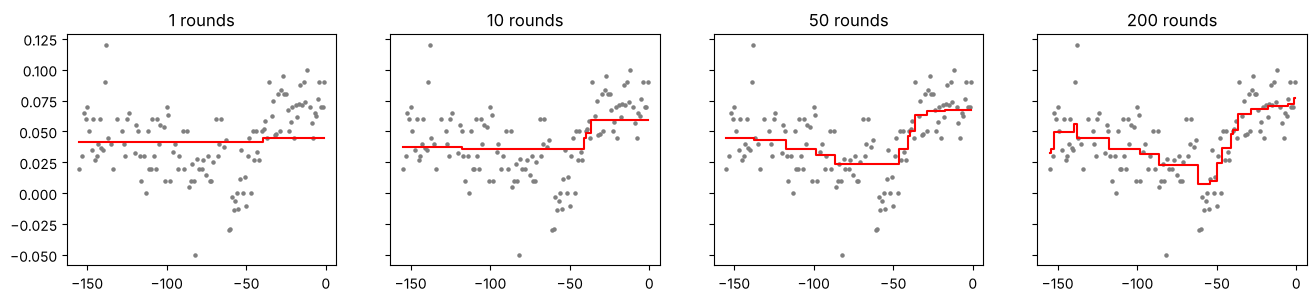

In [2]:
polls = pd.read_csv(DATA + "polls_2008.csv")
Xp, yp = polls[["day"]], polls["margin"].to_numpy()
eta, M = 0.1, 200
f_hat = np.full(len(yp), yp.mean()); fits = {}
for m in range(1, M + 1):
    r = yp - f_hat                                             # 1. residuals
    stump = DecisionTreeRegressor(max_depth=1).fit(Xp, r)      # 2. small tree
    f_hat = f_hat + eta * stump.predict(Xp)                    # 3. small step
    if m in (1, 10, 50, 200): fits[m] = f_hat.copy()

fig, ax = plt.subplots(1, 4, figsize=(16, 3), sharey=True)
for a, (m, f) in zip(ax, fits.items()):
    a.scatter(polls.day, yp, s=5, c="grey"); a.step(polls.day, f, c="red", where="mid")
    a.set_title(f"{m} rounds")
plt.show()

## GBM: digits 2 vs. 7

In [3]:
train = pd.read_csv(DATA + "mnist_27_train.csv"); test = pd.read_csv(DATA + "mnist_27_test.csv")
Xtr, ytr = train[["x_1", "x_2"]], (train["y"] == 7).astype(int)
Xte, yte = test[["x_1", "x_2"]], (test["y"] == 7).astype(int)

true_p = pd.read_csv(DATA + "mnist_27_true_p.csv")
g1 = np.sort(true_p["x_1"].unique()); g2 = np.sort(true_p["x_2"].unique())

def plot_cond_prob(p, ax, title=""):
    tp = true_p.assign(p=p).pivot(index="x_2", columns="x_1", values="p")
    ax.imshow(tp.values, origin="lower", extent=[g1.min(), g1.max(), g2.min(), g2.max()],
              aspect="auto", cmap="RdBu", vmin=0, vmax=1)
    ax.contour(tp.columns, tp.index, tp.values, levels=[0.5], colors="black")
    ax.set_title(title); ax.set_xlabel("x_1"); ax.set_ylabel("x_2")

In [4]:
grid = {"n_estimators": [50, 100, 200, 400], "max_depth": [1, 3, 5]}
gbm = GridSearchCV(GradientBoostingClassifier(learning_rate=0.05, min_samples_leaf=10, random_state=42),
                   grid, cv=5).fit(Xtr, ytr)
print(gbm.best_params_)
print("test accuracy:", round(gbm.score(Xte, yte), 3))

{'max_depth': 5, 'n_estimators': 50}
test accuracy: 0.83


## XGBoost: early stopping by cross-validation
Train loss keeps falling; CV loss bottoms out.

best rounds: 89


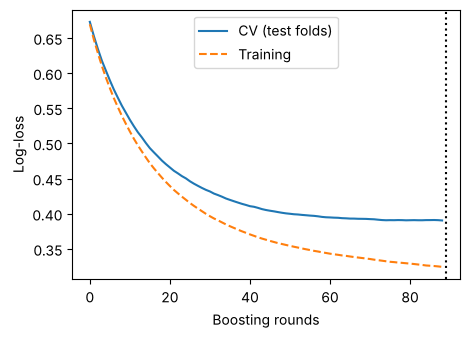

In [5]:
dtrain = xgb.DMatrix(Xtr, label=ytr)
params = {"objective": "binary:logistic", "eval_metric": "logloss", "eta": 0.05,
          "max_depth": 3, "subsample": 0.8, "colsample_bytree": 1}
cv = xgb.cv(params, dtrain, num_boost_round=1000, nfold=5, early_stopping_rounds=20, seed=42)
best_n = int(cv["test-logloss-mean"].idxmin()) + 1
print("best rounds:", best_n)
plt.figure(figsize=(5, 3.5))
plt.plot(cv["test-logloss-mean"], label="CV (test folds)")
plt.plot(cv["train-logloss-mean"], "--", label="Training")
plt.axvline(best_n, ls=":", c="k"); plt.xlabel("Boosting rounds"); plt.ylabel("Log-loss"); plt.legend(); plt.show()

In [6]:
xgb_fit = xgb.train(params, dtrain, num_boost_round=best_n)
p_hat = xgb_fit.predict(xgb.DMatrix(Xte))
print("test accuracy:", round(((p_hat > 0.5) == yte).mean(), 3))

test accuracy: 0.81


## Comparing the methods

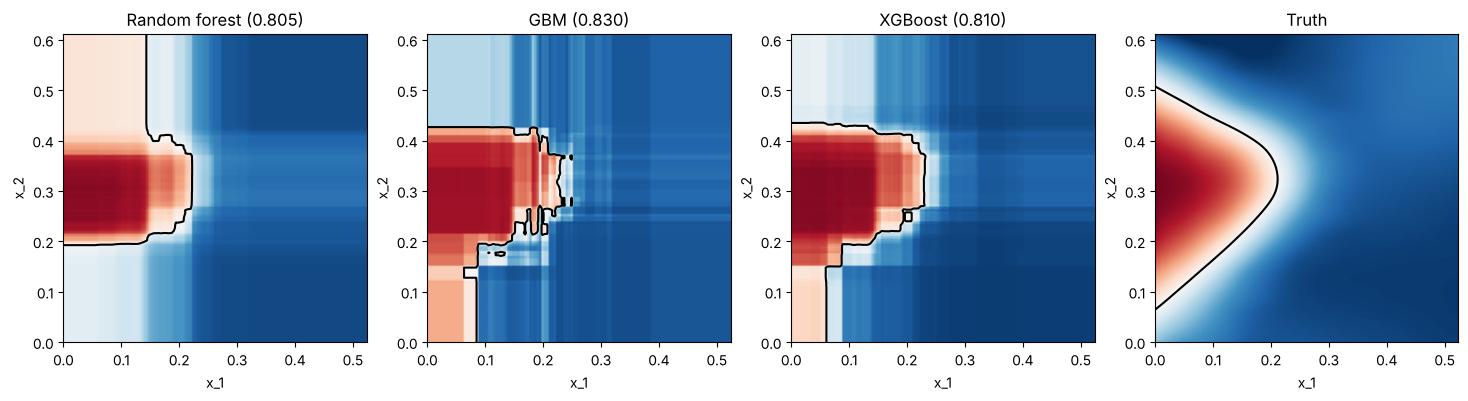

In [7]:
rf = RandomForestClassifier(n_estimators=500, min_samples_leaf=31, random_state=1).fit(Xtr, ytr)
grid_X = true_p[["x_1", "x_2"]]
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
plot_cond_prob(rf.predict_proba(grid_X)[:, 1], ax[0], f"Random forest ({rf.score(Xte, yte):.3f})")
plot_cond_prob(gbm.predict_proba(grid_X)[:, 1], ax[1], f"GBM ({gbm.score(Xte, yte):.3f})")
plot_cond_prob(xgb_fit.predict(xgb.DMatrix(grid_X)), ax[2],
               f"XGBoost ({((p_hat > 0.5) == yte).mean():.3f})")
plot_cond_prob(true_p["p"], ax[3], "Truth"); plt.show()

## Tuning XGBoost over a small grid
The scikit-learn wrapper `xgb.XGBClassifier` also works inside `GridSearchCV`; here we loop over `xgb.cv` as in the R slides.

In [8]:
res = []
for depth in (2, 3, 5):
    for e in (0.05, 0.1):
        cvi = xgb.cv({**params, "max_depth": depth, "eta": e}, dtrain, num_boost_round=1000,
                     nfold=5, early_stopping_rounds=20, seed=42)
        res.append({"max_depth": depth, "eta": e, "nrounds": len(cvi),
                    "logloss": cvi["test-logloss-mean"].min()})
pd.DataFrame(res).sort_values("logloss")

,max_depth,eta,nrounds,logloss
0,2,0.05,145,0.387751
2,3,0.05,89,0.390398
1,2,0.10,83,0.390655
3,3,0.10,43,0.392524
4,5,0.05,64,0.403125
5,5,0.10,26,0.405807
